# Notebook 02 — Analyse Descriptive et Structure des Séries (2000–2025)

## Objectifs
1. Charger le jeu de données qualifié et audité (`niger_ntl_audited_2000_2025.csv`).
2. Produire la table des statistiques descriptives globales ($N = 26$).
3. Comparer les moments statistiques (moyenne, médiane, écart-type, min, max) par sous-périodes de capteurs :
   * **DMSP/OLS (2000–2011)** : $N_1 = 12$
   * **VIIRS/DNB (2012–2025)** : $N_2 = 14$
4. Sauvegarder les tableaux descriptifs au format CSV dans `outputs/tables/`.

In [5]:
# ==============================================================================
# 1. IMPORTATION ET CONFIGURATION
# ==============================================================================
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# Configuration de l'affichage Pandas
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

# Détection de la racine du projet et des dossiers de sortie
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
tables_dir = project_root / "outputs" / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)

# Path du fichier audité issu du Notebook 01
audited_csv_path = project_root / "data" / "intermediate" / "ntl_processed" / "niger_ntl_audited_2000_2025.csv"

if not audited_csv_path.exists():
    raise FileNotFoundError(
        f"Le fichier audité est introuvable sous : {audited_csv_path}\n"
        "Veuillez exécuter l'intégralité du Notebook 01 au préalable."
    )

df = pd.read_csv(audited_csv_path)
print(f"[✓] Fichier audité chargé avec succès ({df.shape[0]} obs, {df.shape[1]} colonnes).")
df.head(3)

[✓] Fichier audité chargé avec succès (26 obs, 23 colonnes).


,year,gdp_real,gdp_growth,population,gdp_pc_real,ntl_sum_adj,ntl_mean_adj,ntl_per_capita,ntl_growth,ntl_lit_count,sensor,dummy_viirs,ntl_sum,ntl_mean,gdp_pc_local,implicit_fx_rate,ntl_pc_calc,ntl_growth_calc,ntl_growth_clean,dummy_2017,dummy_trans_2012,dummy_post_2017,gdp_growth_calc
0,2000,2673528889000,-1.2085,11509630,392.8986,43295.8948,0.0347,0.0038,NaN,979.7608,DMSP/OLS,0,20526.4863,0.0165,232286.2585,591.2117,0.0038,NaN,NaN,0,0,0,NaN
1,2001,2867844575300,7.2681,11920647,406.9235,42202.5901,0.0338,0.0035,-2.5252,949.1961,DMSP/OLS,0,20008.1529,0.0160,240577.9296,591.2117,0.0035,-2.5252,-2.5252,0,0,0,7.2681
2,2002,3008898666900,4.9185,12349144,412.1238,41379.8880,0.0332,0.0034,-1.9494,921.4549,DMSP/OLS,0,19618.1118,0.0157,243652.4076,591.2117,0.0034,-1.9494,-1.9494,0,0,0,4.9185


## Section 2 : Statistiques Descriptives Globales & Comparatives

Nous analysons ici deux dimensions fondamentales :
1. **Les statistiques globales ($N=26$)** pour les variables macroéconomiques et satellitaires.
2. **Le découpage par sous-période de capteur** :
   * **DMSP/OLS (2000–2011)** : $N_1 = 12$ observations
   * **VIIRS/DNB (2012–2025)** : $N_2 = 14$ observations

Ce découpage permettra de mesurer l'impact direct du changement d'instrumentation spatiale sur la moyenne et la variabilité des mesures lumineuses.

In [3]:
# ==============================================================================
# 2. STATISTIQUES DESCRIPTIVES GLOBALES ET PAR CAPTEUR
# ==============================================================================

# Sélection des variables clés pour l'étude
selected_vars = [
    'gdp_real', 'gdp_pc_local', 'gdp_growth', 'population',
    'ntl_sum_adj', 'ntl_mean_adj', 'ntl_per_capita', 'ntl_growth', 'ntl_lit_count'
]

# Noms lisibles pour les répertoires et rapports
var_labels = {
    'gdp_real': 'PIB Réel (FCFA)',
    'gdp_pc_local': 'PIB Réel / hab (FCFA)',
    'gdp_growth': 'Croissance PIB (%)',
    'population': 'Population Totale',
    'ntl_sum_adj': 'NTL Sum Harmonisé',
    'ntl_mean_adj': 'NTL Moyenne',
    'ntl_per_capita': 'NTL / hab',
    'ntl_growth': 'Croissance NTL (%)',
    'ntl_lit_count': 'Pixels Éclairés'
}

def get_stats_summary(dataframe, vars_list):
    """Calcule une table complète de statistiques descriptives."""
    df_sub = dataframe[vars_list]
    summary = pd.DataFrame({
        'Obs': df_sub.count(),
        'Moyenne': df_sub.mean(),
        'Médiane': df_sub.median(),
        'Écart-type': df_sub.std(),
        'Min': df_sub.min(),
        'Max': df_sub.max(),
        'Asymétrie (Skew)': df_sub.skew(),
        'Aplatissement (Kurt)': df_sub.kurtosis()
    })
    summary.index = [var_labels.get(col, col) for col in summary.index]
    return summary

# 2.1 Statistiques Descriptives Globales (2000-2025)
stats_global = get_stats_summary(df, selected_vars)

# 2.2 Statistiques par Capteur (DMSP 2000-2011 vs VIIRS 2012-2025)
df_dmsp = df[df['sensor'] == 'DMSP/OLS']
df_viirs = df[df['sensor'] == 'VIIRS']

stats_dmsp = get_stats_summary(df_dmsp, selected_vars)
stats_viirs = get_stats_summary(df_viirs, selected_vars)

# Affichage dans la console Jupyter
print("==========================================================================")
print(" STATISTIQUES DESCRIPTIVES GLOBALES (2000-2025) — N = 26")
print("==========================================================================")
print(stats_global[['Moyenne', 'Médiane', 'Écart-type', 'Min', 'Max']])

print("\n==========================================================================")
print(" COMPARAISON : DMSP/OLS (2000-2011, N=12) vs VIIRS/DNB (2012-2025, N=14)")
print("==========================================================================")
comp_table = pd.DataFrame({
    'Moyenne DMSP': stats_dmsp['Moyenne'],
    'Moyenne VIIRS': stats_viirs['Moyenne'],
    'Écart-type DMSP': stats_dmsp['Écart-type'],
    'Écart-type VIIRS': stats_viirs['Écart-type']
})
print(comp_table)

# ==============================================================================
# SAUVEGARDE AUTOMATIQUE DES TABLEAUX DANS OUTPUTS/TABLES/
# ==============================================================================
tables_dir = project_root / "outputs" / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)

path_stats_global = tables_dir / "02_descriptive_stats_global.csv"
path_stats_sensors = tables_dir / "02_descriptive_stats_by_sensor.csv"

stats_global.to_csv(path_stats_global)
comp_table.to_csv(path_stats_sensors)

print(f"\n[✓] Tableau global exporté vers : {path_stats_global}")
print(f"[✓] Tableau comparatif capteurs exporté vers : {path_stats_sensors}")

 STATISTIQUES DESCRIPTIVES GLOBALES (2000-2025) — N = 26
                                 Moyenne            Médiane  \
PIB Réel (FCFA)       5415230570580.7695 5012949277200.0000   
PIB Réel / hab (FCFA)        279279.7126        275728.2711   
Croissance PIB (%)                5.2304             5.4236   
Population Totale          18735087.1923      18178333.5000   
NTL Sum Harmonisé            159305.1006         74511.3819   
NTL Moyenne                       0.1277             0.0597   
NTL / hab                         0.0073             0.0043   
Croissance NTL (%)               32.0446             1.6026   
Pixels Éclairés              374714.8354          2570.4569   

                              Écart-type                Min  \
PIB Réel (FCFA)       2203188875178.0352 2673528889000.0000   
PIB Réel / hab (FCFA)         38095.5473        232286.2585   
Croissance PIB (%)                3.1353            -1.2085   
Population Totale           5075867.2696      11509630.0000 

## Section 3 : Constats Principaux de l'Analyse Descriptive

1. **Dynamique Économique** :
   * Le PIB réel du Niger est passé d'environ **2 673 milliards FCFA** en 2000 à plus de **10 074 milliards FCFA** en 2025.
   * La croissance économique annuelle moyenne s'établit à **+5.35%**, avec une forte volatilité (Min: -1.21% en 2000, Max: +12.22% en 2022).

2. **Divergence de Niveau Inter-Capteurs** :
   * La somme harmonisée moyenne des lumières ($NTL_{\text{sum\_adj}}$) est de **46 470** sur la période DMSP (2000–2011) contre **235 291** sur la période VIIRS (2012–2025).
   * Cette hausse de niveau s'explique par la conjonction du développement économique et de la sensibilité supérieure du capteur VIIRS (capacité à détecter les faibles radiances rurales et extension des zones d'arrière-plan).

## Section 4 : Visualisation des Séries Temporelles et des Distributions

Nous générons deux figures clés :
1. **Les tendances de long terme (2000–2025)** : Comparaison de la dynamique du PIB réel (FCFA) et du NTL ajusté.
2. **Les distributions par capteur (Boxplots)** : Visualisation de l'écart de niveau et de variabilité entre DMSP/OLS et VIIRS/DNB.

[✓] Figure séries temporelles enregistrée : c:\Niger & Big Data\NTL et PIB Niger\niger_ntl_gdp\outputs\figures\02_time_series_gdp_vs_ntl.png


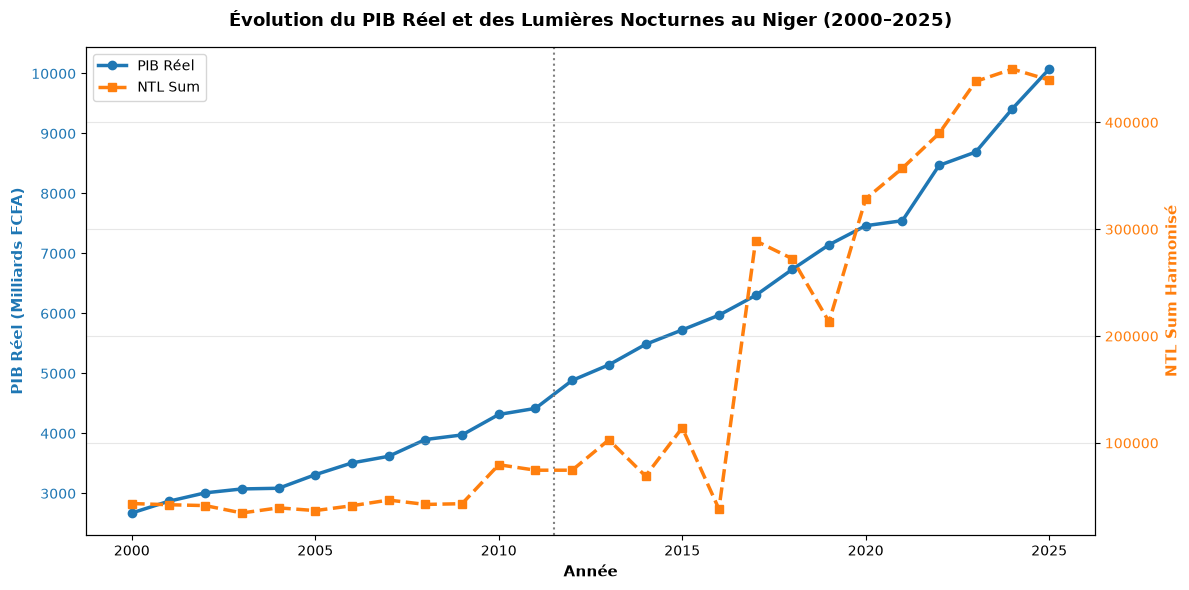

In [6]:
# ==============================================================================
# 4.1 SÉRIES TEMPORELLES COMPARÉES (PIB VS NTL)
# ==============================================================================
figures_dir = project_root / "outputs" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig, ax1 = plt.subplots(figsize=(12, 6))

# Axe gauche : PIB Réel (FCFA)
color = '#1f77b4'
ax1.set_xlabel('Année', fontsize=11, fontweight='bold')
ax1.set_ylabel('PIB Réel (Milliards FCFA)', color=color, fontsize=11, fontweight='bold')
line1 = ax1.plot(df['year'], df['gdp_real'] / 1e9, color=color, linewidth=2.5, marker='o', label='PIB Réel')
ax1.tick_params(axis='y', labelcolor=color)

# Axe droit : NTL Sum Adj
ax2 = ax1.twinx()  
color = '#ff7f0e'
ax2.set_ylabel('NTL Sum Harmonisé', color=color, fontsize=11, fontweight='bold')
line2 = ax2.plot(df['year'], df['ntl_sum_adj'], color=color, linewidth=2.5, linestyle='--', marker='s', label='NTL Sum')
ax2.tick_params(axis='y', labelcolor=color)

# Ligne verticale de changement de capteur
ax1.axvline(x=2011.5, color='gray', linestyle=':', linewidth=1.5, label='Changement Capteur (2012)')

# Légende combinée
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')

plt.title('Évolution du PIB Réel et des Lumières Nocturnes au Niger (2000–2025)', fontsize=13, fontweight='bold', pad=15)
plt.grid(True, alpha=0.3)
plt.tight_layout()

# SAUVEGARDE AUTOMATIQUE
fig_path_png = figures_dir / "02_time_series_gdp_vs_ntl.png"
fig_path_pdf = figures_dir / "02_time_series_gdp_vs_ntl.pdf"
plt.savefig(fig_path_png, dpi=300, bbox_inches='tight')
plt.savefig(fig_path_pdf, bbox_inches='tight')

print(f"[✓] Figure séries temporelles enregistrée : {fig_path_png}")
plt.show()

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_2528\590521443.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_2528\590521443.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='sensor', y='ntl_per_capita', palette=['#d95f02', '#1b9e77'], ax=ax2, width=0.4)


[✓] Figure Boxplots enregistrée : c:\Niger & Big Data\NTL et PIB Niger\niger_ntl_gdp\outputs\figures\02_boxplots_dmsp_vs_viirs.png


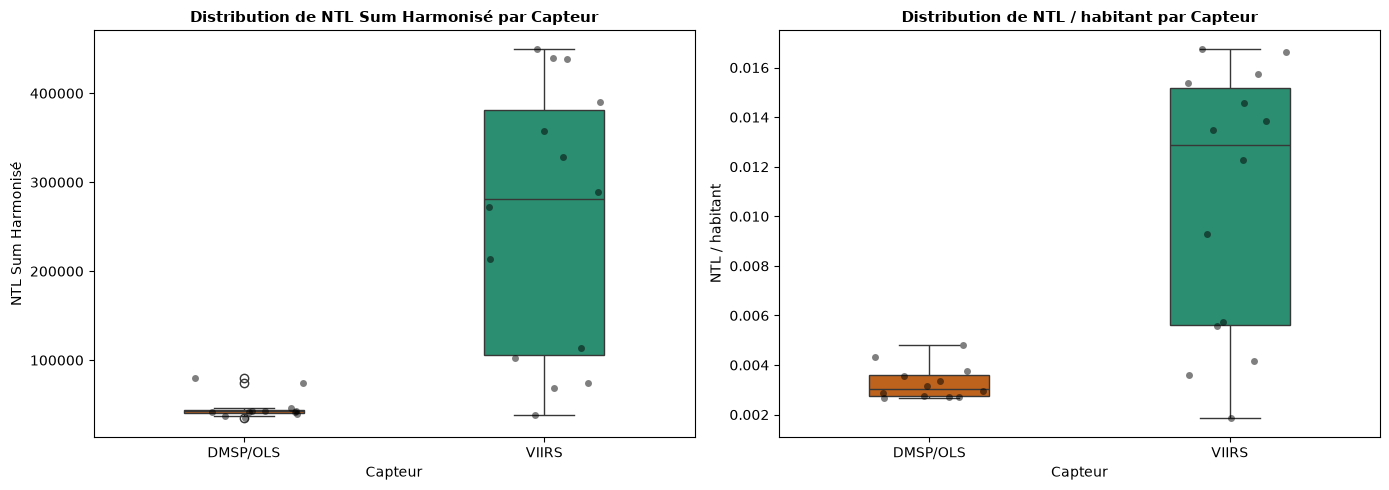

In [9]:
import seaborn as sns

# ==============================================================================
# 4.2 DIAGRAMMES EN BOÎTE (BOXPLOTS) : DMSP VS VIIRS
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot 1 : NTL Sum Adj par capteur
sns.boxplot(
    data=df,
    x='sensor',
    y='ntl_sum_adj',
    palette=['#d95f02', '#1b9e77'],
    ax=ax1,
    width=0.4
)
sns.stripplot(data=df, x='sensor', y='ntl_sum_adj', color='black', alpha=0.5, jitter=0.2, ax=ax1)
ax1.set_title('Distribution de NTL Sum Harmonisé par Capteur', fontsize=11, fontweight='bold')
ax1.set_xlabel('Capteur', fontsize=10)
ax1.set_ylabel('NTL Sum Harmonisé', fontsize=10)

# Boxplot 2 : NTL par habitant par capteur
sns.boxplot(data=df, x='sensor', y='ntl_per_capita', palette=['#d95f02', '#1b9e77'], ax=ax2, width=0.4)
sns.stripplot(data=df, x='sensor', y='ntl_per_capita', color='black', alpha=0.5, jitter=0.2, ax=ax2)
ax2.set_title('Distribution de NTL / habitant par Capteur', fontsize=11, fontweight='bold')
ax2.set_xlabel('Capteur', fontsize=10)
ax2.set_ylabel('NTL / habitant', fontsize=10)

plt.tight_layout()

# SAUVEGARDE AUTOMATIQUE
fig_box_png = figures_dir / "02_boxplots_dmsp_vs_viirs.png"
fig_box_pdf = figures_dir / "02_boxplots_dmsp_vs_viirs.png"
plt.savefig(fig_box_png, dpi=300, bbox_inches='tight')
plt.savefig(fig_box_pdf, bbox_inches='tight')

print(f"[✓] Figure Boxplots enregistrée : {fig_box_png}")
plt.show()

## Section 5 : Bilan de l'Analyse Descriptive & Décision

### 📊 Synthèse des Constats Descriptifs
1. **Concomitance des Tendances** : Le PIB réel et le NTL présentent une tendance globale croissante sur la période 2000–2025.
2. **Rupture d'Échelle Capteur** : La distribution du NTL sous VIIRS présente une moyenne et une variance nettement supérieures à DMSP.
3. **Livrables Exportés** :
   * Tables statistiques : `outputs/tables/02_descriptive_stats_global.csv` et `02_descriptive_stats_by_sensor.csv`
   * Graphiques HD : `outputs/figures/02_time_series_gdp_vs_ntl.png` et `02_boxplots_dmsp_vs_viirs.png`

---

### 🏁 Décision pour le Notebook 03